# задание 1 - дд 7.10 23.59
# Построение модели вероятности дефолта на датасете give me some credit

## 1. загрузка и очистка данных:

In [1]:
!pip install lightgbm shap -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import shap
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# настройки отображения
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

In [2]:
df = pd.read_csv('cs-training.csv', sep=';')

df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


интерпретация столбцов:
1. SeriousDlqin2yrs - cерьезная просрочка в течение 2 лет (0 - хорошка, 1 - плохой)

2. RevolvingUtilizationOfUnsecuredLines - насколько сильно человек залез в кредитки (чем выше число, тем ближе человек к финансовому краю)

3. NumberOfTime30-59DaysPastDueNotWorse - сколько раз за последние 2 года человек задерживал платеж на месяц

4. NumberOfTime60-89DaysPastDueNotWorse - задержка на 2 месяца

5. NumberOfTimes90DaysLate - колво просрочек 90+ дней

6. DebtRatio - сколько процентов от зарплаты уходит на выплаты

7. NumberOfOpenCreditLinesAndLoans - колво открытых кредитов и займов

8. NumberRealEstateLoansOrLines - колво кредитов по недвижке и кредитных линий

9. NumberOfDependents - сколько человек находится на обеспечении заемщика

In [3]:
if 'Unnamed: 0' in df.columns:
    df = df.drop('Unnamed: 0', axis=1)

print("пропуски до обработки:\n", df.isnull().sum())

# пропуски медианой
df['MonthlyIncome'] = df['MonthlyIncome'].fillna(df['MonthlyIncome'].median())
df['NumberOfDependents'] = df['NumberOfDependents'].fillna(df['NumberOfDependents'].median())

print("\nпропуски после обработки:\n", df.isnull().sum())

# разделяем на признаки X и цель y
X = df.drop('SeriousDlqin2yrs', axis=1)
y = df['SeriousDlqin2yrs']

print(f"\nРазмер данных: {X.shape}")
print(f"доля дефолтов: {y.mean():.4f}")

пропуски до обработки:
 SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

пропуски после обработки:
 SeriousDlqin2yrs                        0
RevolvingUtilizationOfUnsecuredLines    0
age                                     0
NumberOfTime30-59DaysPastDueNotWorse    0
DebtRatio                               0
MonthlyIncome                           0
NumberOfOpenCreditLinesAndLoans         0
NumberOfTimes90DaysLate                 0
NumberRealEstateLoansOrLines            0
NumberOfTime60-89DaysPastDueNotWorse    0
NumberOfD

In [4]:
df.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [5]:
df['Income_is_missing'] = df['MonthlyIncome'].isnull().astype(int)

## 2. разделение выборки на train и test:

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"обуч выборка: {X_train.shape}, валидационная: {X_val.shape}")

обуч выборка: (120000, 10), валидационная: (30000, 10)


## 3. бустинг (LightGBM)

In [8]:
model = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

model.fit(X_train, y_train)

# вероятности
y_pred_proba = model.predict_proba(X_val)[:, 1]

In [9]:
# ROC-AUC
roc_auc = roc_auc_score(y_val, y_pred_proba)
print(f"ROC-AUC на валидации: {roc_auc:.4f}")

ROC-AUC на валидации: 0.8686


## 4. SHAP


/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


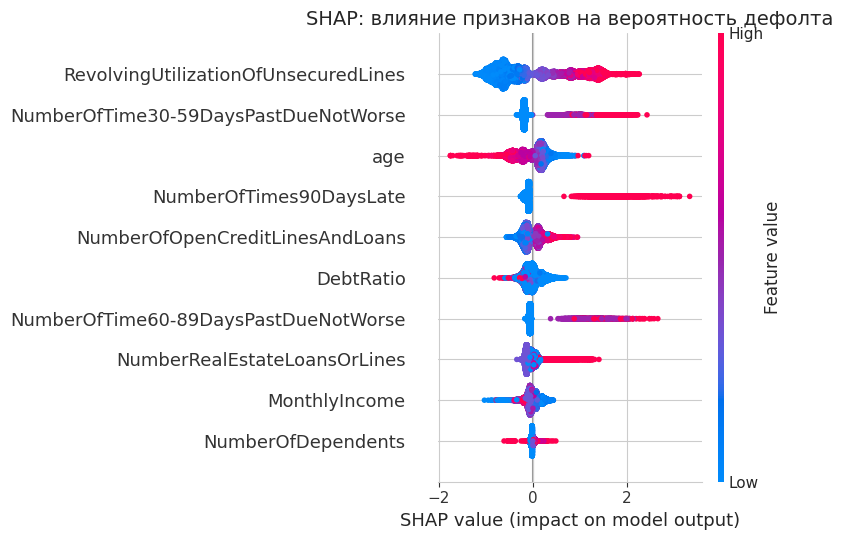

график сохранен


In [11]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_val)

# для бин классификации LightGBM возвращ список из двух массивов
# нужен массив для класса 1 (дефолт)
if isinstance(shap_values, list):
    shap_values_to_plot = shap_values[1]
else:
    shap_values_to_plot = shap_values

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_to_plot, X_val, show=False)
plt.title("SHAP: влияние признаков на вероятность дефолта", fontsize=14)
plt.tight_layout()

plt.savefig('shap_summary.png', dpi=300, bbox_inches='tight')
plt.show()

print("график сохранен")

нак всякий случай проверка важности признаков

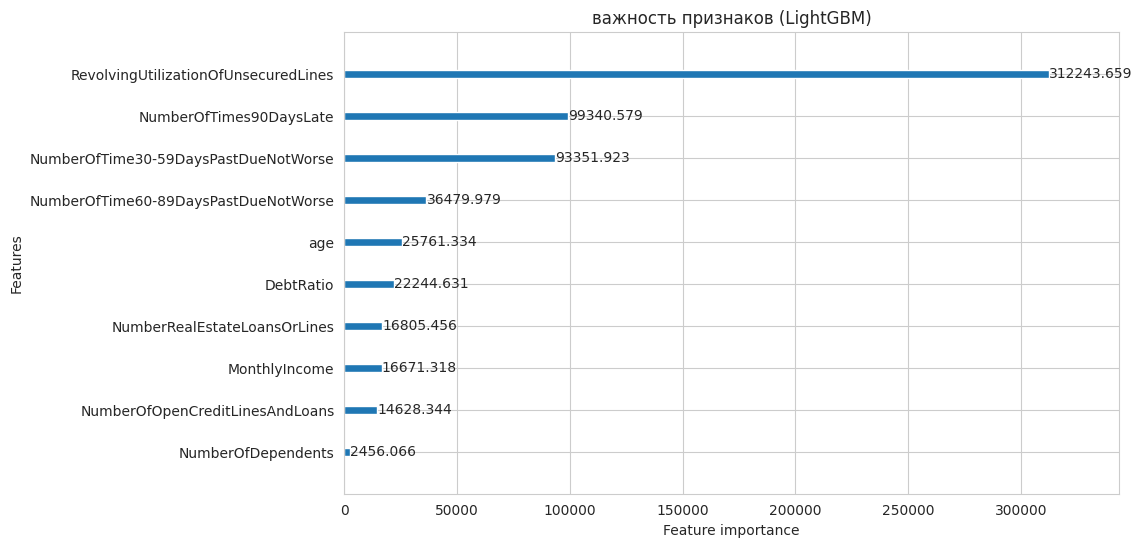

In [12]:
lgb.plot_importance(model, figsize=(10, 6), importance_type='gain')
plt.title("важность признаков (LightGBM)")
plt.show()